# Part 3 — locality, windows, and hierarchy

Part 2 improved the training of our flat ViT. Part 3 investigates changes to
the architecture, beginning with spatial window mechanics. The current
milestone partitions a grid into local windows and reconstructs it.

Follow the same flow as Parts 1 and 2: import components from Python modules,
inspect their behavior in small examples, then prepare the shared data split.
The revised article opening is in [article-results/part3/draft.md](article-results/part3/draft.md).

In [1]:
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import torch

from models.part3_swin import window_partition, window_reverse
from pipeline.experiment_utils import reset_seed, save_json
from visualization.windows import display_window_partition

SEED = 0
SPLIT_SEED = 0
BATCH_SIZE = 32
IMAGE_SIZE = 224
DATA_DIR = Path("data")
RESULTS_DIR = Path("artifacts/part3") / datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S_UTC")
device = torch.device("cuda" if torch.cuda.is_available() else
                      "mps" if torch.backends.mps.is_available() else "cpu")
reset_seed(SEED)

print(f"Device: {device}; results: {RESULTS_DIR}")

Device: cpu; results: artifacts/part3/20261117_041223_UTC


## Window partitioning and reconstruction

Use channels-last grids, `[B, H, W, C]`. In the model, H and W describe
token positions. A square window of side M contains M × M neighboring
tokens. The helpers currently require H and W to be divisible by M.

Start with token IDs so we can see the spatial ordering directly. The
top-left 2 × 2 window should contain `[[0, 1], [4, 5]]`. Windows proceed
left to right, then top to bottom, independently for each batch item.

Original token grid:
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15]])
Windows in spatial order:
tensor([[[ 0,  1],
         [ 4,  5]],

        [[ 2,  3],
         [ 6,  7]],

        [[ 8,  9],
         [12, 13]],

        [[10, 11],
         [14, 15]]])
Reconstruction maximum difference: 0


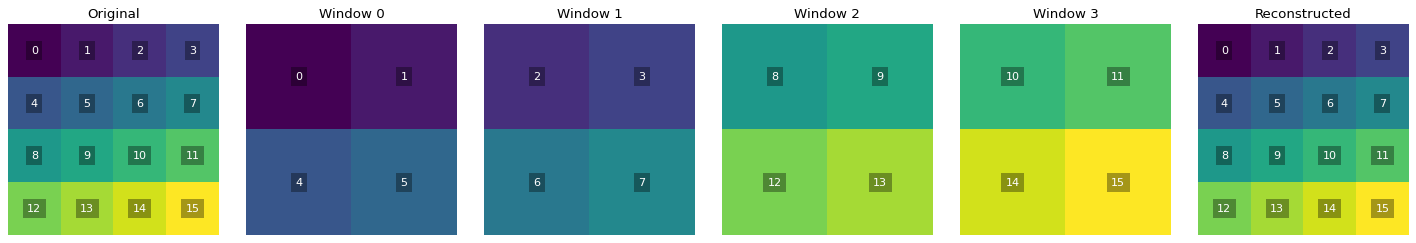

In [2]:
token_ids = torch.arange(16, device=device).reshape(1, 4, 4, 1)
small_windows = window_partition(token_ids, window_size=2)
restored_ids = window_reverse(small_windows, window_size=2, height=4, width=4)

print("Original token grid:")
print(token_ids[0, :, :, 0].cpu())
print("Windows in spatial order:")
print(small_windows[:, :, :, 0].cpu())
print("Reconstruction maximum difference:", (restored_ids - token_ids).abs().max().item())
window_figure = display_window_partition(token_ids, small_windows, restored_ids, annotate=True)

## From image size to token-grid size

Patch size and window size use different units. With 4 × 4 pixel patches,
a 224 × 224 image produces a 56 × 56 token grid. A 7 × 7 token window
contains 49 tokens, and there are 64 windows per image at this stage.

The following random features illustrate tensor shapes only. They are
not learned image embeddings. Partitioning leaves each token's channels
intact and keeps the two batch items separate.

In [3]:
PATCH_SIZE = 4
WINDOW_SIZE = 7
EMBEDDING_DIM = 32
grid_height = grid_width = IMAGE_SIZE // PATCH_SIZE

token_grid = torch.randn(2, grid_height, grid_width, EMBEDDING_DIM, device=device)
token_windows = window_partition(token_grid, WINDOW_SIZE)
restored_tokens = window_reverse(token_windows, WINDOW_SIZE, grid_height, grid_width)

print("Token grid:", tuple(token_grid.shape))
print("Windows:", tuple(token_windows.shape))
print("Tokens per window:", WINDOW_SIZE ** 2)
print("Windows per image:", (grid_height // WINDOW_SIZE) * (grid_width // WINDOW_SIZE))
print("Reconstruction maximum difference:", (restored_tokens - token_grid).abs().max().item())

Token grid: (2, 56, 56, 32)
Windows: (128, 7, 7, 32)
Tokens per window: 49
Windows per image: 64
Reconstruction maximum difference: 0.0


## Optional RGB illustration

This example partitions raw pixels to make the operation visible. It does
not perform Swin patch embedding or attention. `ToTensor` produces
`[C, H, W]`; convert it to `[B, H, W, C]` before calling the helper.
If the local image is absent, the example is skipped.

In [4]:
from PIL import Image
from torchvision.transforms import ToTensor

image_path = DATA_DIR / "image_8765cd2c.jpg"
if image_path.is_file():
    with Image.open(image_path) as image:
        image = image.convert("RGB").resize((IMAGE_SIZE, IMAGE_SIZE))
    image_grid = ToTensor()(image).unsqueeze(0).permute(0, 2, 3, 1).to(device)
    pixel_window_size = 28
    image_windows = window_partition(image_grid, pixel_window_size)
    restored_image = window_reverse(image_windows, pixel_window_size, IMAGE_SIZE, IMAGE_SIZE)

    print("RGB grid:", tuple(image_grid.shape))
    print("Pixel windows:", tuple(image_windows.shape))
    print("Reconstruction maximum difference:", (restored_image - image_grid).abs().max().item())
    image_figure = display_window_partition(image_grid, image_windows, restored_image)
else:
    print(f"Optional RGB illustration skipped: {image_path} was not found.")

Optional RGB illustration skipped: data/image_8765cd2c.jpg was not found.


## Attention-score counts as the grid grows

For N = H × W tokens, global attention has N² score entries per head.
With M × M windows, the total is (N / M²) × (M²)² = N M².
Keeping M fixed makes this count linear in N. Doubling both grid
dimensions quadruples N: global score counts grow 16× and window score
counts grow 4×.

These are mathematical counts, excluding special tokens. They are not
measured latency, peak memory, or total model FLOPs; projections, MLPs,
data movement, and implementation details also affect runtime.

In [5]:
score_counts = []
print(f"{'Grid':<12} {'Tokens':>8} {'Global scores/head':>20} {'Window scores/head':>20}")
for side in (14, 28, 56, 112):
    num_tokens = side * side
    row = dict(
        grid_height=side, grid_width=side, window_size=WINDOW_SIZE,
        tokens=num_tokens, global_scores_per_head=num_tokens ** 2,
        window_scores_per_head=num_tokens * WINDOW_SIZE ** 2,
    )
    score_counts.append(row)
    print(f"{side:>3} x {side:<6} {num_tokens:>8,} {row['global_scores_per_head']:>20,} {row['window_scores_per_head']:>20,}")

save_json(RESULTS_DIR / "attention_score_counts.json", score_counts)

Grid           Tokens   Global scores/head   Window scores/head
 14 x 14          196               38,416                9,604
 28 x 28          784              614,656               38,416
 56 x 56        3,136            9,834,496              153,664
112 x 112      12,544          157,351,936              614,656


## Prepare the same Imagenette split for later training

Run this section when preparing the classification experiments. It loads
Imagenette and retains Part 2's stratified 80/20 split of the official
training pool with split seed 0. It saves the ordered sample manifest and
split membership. The official validation split remains the held-out
final test set. No model training is started here.

In [ ]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset

from datasets.imagenette import download_imagenette_dataset

pool = download_imagenette_dataset(DATA_DIR, split="train", image_size=IMAGE_SIZE)
labels = np.array([label for _, label in pool._samples])
train_indices, val_indices = train_test_split(np.arange(len(pool)), test_size=0.2, random_state=SPLIT_SEED, stratify=labels)
train_data = Subset(pool, train_indices.tolist())
validation_data = Subset(pool, val_indices.tolist())
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
np.savez(RESULTS_DIR / "split_indices.npz", train=train_indices, validation=val_indices)
save_json(RESULTS_DIR / "dataset_manifest.json", {
    "dataset": "Imagenette", "distribution": "320px", "official_split": "train",
    "split_seed": SPLIT_SEED, "class_to_idx": pool.class_to_idx,
    "ordered_samples": [
        {"image": str(Path(path).relative_to(Path(pool._image_root))), "label": int(label)}
        for path, label in pool._samples
    ],
})
print(f"Training: {len(train_data)}; internal validation: {len(validation_data)}")

## Next component — attention within each window

The current helper rearranges tokens; it does not calculate attention.
Next, flatten each window to `[B_windows, M*M, C]`, implement the QKV
projections and scaled dot-product attention, and project back to the
same shape. Add relative position bias, then introduce shifted windows
and their mask in a later milestone.

Fixed window attention restricts communication across boundaries. How
can the next layer connect tokens that belonged to different windows?